# Notebook 08: Total-power normalisation control

The sex association reported in Notebooks 04–05 rests on absolute band power. Absolute power at the scalp is sensitive to factors that have nothing to do with cortical activity: skull thickness, scalp conductivity, electrode contact quality, and hair. Several of these differ systematically between men and women — skull thickness in particular is an established modulator of measured alpha amplitude (Hagemann et al., 2008).

This gives two competing explanations for the finding:

- **Global gain.** Absolute power differs overall between the sexes for anatomical or contact reasons, and NMF recovers that as a distributed pattern. The *shape* of the spectrum across channels and bands would be unchanged.
- **Topographic difference.** The relative distribution of power across channels and bands differs between the sexes, over and above any overall scaling — the pattern reported by Jochmann et al. (2023).

Normalising each participant by their own total power removes the global gain term by construction. If the sex effect survives, it is topographic. If it disappears, it was gain.

This notebook does **not** replace the main pipeline. It re-runs it end to end on normalised data and places the two results side by side.

**Two normalisation variants are run:**

1. **Global** — each participant's 350 features divided by that participant's mean feature value. Removes one scaling factor per participant.
2. **Per-category** — each participant's 70 features within each task category divided by that category's mean for that participant. Also absorbs gain drift across the session (contact degrading over 37 tasks), at the cost of removing any genuine between-category power differences.

Global is the primary analysis and the one that answers Mateo's question directly; per-category is the stricter sensitivity check.

**Inputs:** `outputs/feature_matrix_raw.csv`, `outputs/metadata.csv`, `outputs/nmf_H.csv`, `outputs/omnibus_results.csv`, `outputs/posthoc_per_component.csv`

**Outputs:** `outputs/norm_*` files (one set per variant) plus `outputs/normalisation_comparison.csv` and `outputs/normalisation_control.png`

## Setup

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.decomposition import NMF
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import StandardScaler
from scipy import stats
from scipy.optimize import linear_sum_assignment
from statsmodels.stats.multitest import multipletests
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path(".").resolve().parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Mirror the main pipeline exactly
K_RANGE = list(range(2, 16))
N_INIT = 50
RANDOM_SEED_BASE = 42
MAX_ITER = 500
TOL = 1e-4
CHOSEN_K = 5

N_PERMUTATIONS = 5000
FDR_ALPHA = 0.05
RANDOM_SEED = 42

LOWER_PCT, UPPER_PCT = 2.5, 97.5

SEX_COL = "Gender"          # column name as it stands in outcomes.csv
SEX_ORDER = ["F", "M"]      # fixes the effect-size sign: positive = higher in females

VARIANTS = ["global", "per_category"]
PRIMARY_VARIANT = "global"

report = []
def log(msg=""):
    print(msg)
    report.append(str(msg))

## Load the raw matrix and the original results

In [2]:
raw = pd.read_csv(OUTPUT_DIR / "feature_matrix_raw.csv", index_col="participant_id")
metadata = pd.read_csv(OUTPUT_DIR / "metadata.csv").set_index("participant_id").reindex(raw.index)
H_orig = pd.read_csv(OUTPUT_DIR / "nmf_H.csv", index_col=0)
omnibus_orig = pd.read_csv(OUTPUT_DIR / "omnibus_results.csv")
posthoc_orig = pd.read_csv(OUTPUT_DIR / "posthoc_per_component.csv")

assert (raw.index == metadata.index).all(), "Row alignment broken"
log(f"Raw matrix:      {raw.shape}")
log(f"Original H:      {H_orig.shape}")

categories = sorted({c.split("__")[0] for c in raw.columns})
log(f"Task categories: {categories}")

sex = metadata[SEX_COL]
observed_levels = [v for v in SEX_ORDER if v in set(sex.dropna())]
if len(observed_levels) != 2:
    raise ValueError(f"Expected levels {SEX_ORDER} in '{SEX_COL}', found {sorted(set(sex.dropna()))}")
log(f"Sex distribution: {dict(sex.value_counts())}")

orig_sex_row = omnibus_orig[omnibus_orig["variable"] == SEX_COL].iloc[0]
log(f"\nOriginal omnibus result for sex: stat = {orig_sex_row['observed_stat']:.4f}, "
    f"p_perm = {orig_sex_row['p_perm']:.4f}, p_fdr = {orig_sex_row['p_fdr']:.4f}")

Raw matrix:      (86, 350)
Original H:      (5, 350)
Task categories: ['frontal', 'frontal_central', 'occipital', 'parietal', 'temporal']
Sex distribution: {'M': 44, 'F': 42}

Original omnibus result for sex: stat = 0.2742, p_perm = 0.0002, p_fdr = 0.0034


## Does total power itself differ by sex?

Before normalising anything, test the premise directly. The global-gain explanation requires that overall power differ between the sexes. If it does not, the confound is far less plausible from the outset — and if it does, the normalisation below is doing real work rather than removing nothing.

Total power is summed over all 350 features on the raw (pre-log) scale, then log-transformed for testing.

In [3]:
def rank_biserial_by_sex(values, sex_series):
    """Mann-Whitney U with a FIXED group order. Positive r = higher in females."""
    df = pd.DataFrame({"v": values, "s": sex_series}).dropna()
    f = df.loc[df["s"] == SEX_ORDER[0], "v"].values   # F
    m = df.loc[df["s"] == SEX_ORDER[1], "v"].values   # M
    if len(f) < 3 or len(m) < 3:
        return dict(u=np.nan, p=np.nan, r=np.nan, n_f=len(f), n_m=len(m))
    u, p = stats.mannwhitneyu(f, m, alternative="two-sided")
    r = 2.0 * u / (len(f) * len(m)) - 1.0
    return dict(u=float(u), p=float(p), r=float(r), n_f=len(f), n_m=len(m),
                median_f=float(np.median(f)), median_m=float(np.median(m)))

total_power = raw.sum(axis=1)
log_total = np.log(total_power)

res_total = rank_biserial_by_sex(log_total, sex)
log("Total power (summed across all 350 features), log scale:")
log(f"  females (n={res_total['n_f']}): median log total = {res_total['median_f']:.3f}")
log(f"  males   (n={res_total['n_m']}): median log total = {res_total['median_m']:.3f}")
log(f"  Mann-Whitney: r = {res_total['r']:+.3f}, p = {res_total['p']:.4f}")

# Same check within each task category
cat_rows = []
for cat in categories:
    cols = [c for c in raw.columns if c.startswith(f"{cat}__")]
    r = rank_biserial_by_sex(np.log(raw[cols].sum(axis=1)), sex)
    r["category"] = cat
    cat_rows.append(r)
cat_total_df = pd.DataFrame(cat_rows)[["category", "n_f", "n_m", "median_f", "median_m", "r", "p"]]
log("\nTotal power by task category:")
log(cat_total_df.round(4).to_string(index=False))

if res_total["p"] < 0.05:
    log("\n[NOTE] Total power differs significantly by sex. A global-gain confound is live,")
    log("       and the normalisation below is the appropriate test of it.")
else:
    log("\n[NOTE] Total power does not differ significantly by sex. A pure global-gain")
    log("       explanation is already weak; normalisation should leave the effect intact.")

Total power (summed across all 350 features), log scale:
  females (n=42): median log total = 6.054
  males   (n=44): median log total = 5.913
  Mann-Whitney: r = +0.190, p = 0.1295

Total power by task category:
       category  n_f  n_m  median_f  median_m       r      p
        frontal   42   44    4.5628    4.3816  0.2294 0.0677
frontal_central   42   44    4.4548    4.3141  0.2273 0.0703
      occipital   42   44    4.1545    4.2035 -0.0714 0.5715
       parietal   42   44    4.3306    4.1866  0.2175 0.0832
       temporal   42   44    4.5061    4.3243  0.2240 0.0744

[NOTE] Total power does not differ significantly by sex. A pure global-gain
       explanation is already weak; normalisation should leave the effect intact.


## Build the normalised matrices

Each variant divides by a per-participant mean and then applies the identical downstream transform used in Notebook 01: `log1p` → per-feature winsorisation at 2.5/97.5 → per-feature min–max scaling to [0, 1].

Dividing by the **mean** rather than the sum keeps the values on roughly the same numeric scale as the originals, so the `log1p` step behaves comparably. Dividing by the sum would differ only by a constant factor of 350 and would compress everything into the near-linear region of `log1p`.

In [4]:
def normalise(df, mode):
    """Return a per-participant power-normalised copy of the raw matrix."""
    out = df.copy().astype(float)
    if mode == "global":
        out = out.div(out.mean(axis=1), axis=0)
    elif mode == "per_category":
        for cat in categories:
            cols = [c for c in out.columns if c.startswith(f"{cat}__")]
            out[cols] = out[cols].div(out[cols].mean(axis=1), axis=0)
    else:
        raise ValueError(mode)
    return out

def pipeline_transform(df):
    """log1p -> per-feature winsorise 2.5/97.5 -> per-feature min-max. Mirrors Notebook 01."""
    logged = np.log1p(df)
    lo = logged.quantile(LOWER_PCT / 100, axis=0)
    hi = logged.quantile(UPPER_PCT / 100, axis=0)
    wins = logged.clip(lower=lo, upper=hi, axis=1)
    mn, mx = wins.min(axis=0), wins.max(axis=0)
    rng = (mx - mn).replace(0, 1)
    return (wins - mn) / rng

matrices = {}
for variant in VARIANTS:
    normed = normalise(raw, variant)
    X = pipeline_transform(normed)
    matrices[variant] = X
    log(f"{variant:14s}: shape {X.shape}, range [{X.values.min():.4f}, {X.values.max():.4f}], "
        f"mean {X.values.mean():.4f}, zero-variance features: {int(((X.max()-X.min())==0).sum())}")

global        : shape (86, 350), range [0.0000, 1.0000], mean 0.4426, zero-variance features: 0
per_category  : shape (86, 350), range [0.0000, 1.0000], mean 0.4597, zero-variance features: 0


## NMF stability sweep on the normalised data

Component count is re-selected rather than assumed. If the normalised data support a different k, that is itself informative and should be reported — the comparison below is only meaningful if the decomposition is fit properly on its own terms.

In [5]:
def cosine_similarity_matrix(A, B):
    A_norm = A / (np.linalg.norm(A, axis=1, keepdims=True) + 1e-12)
    B_norm = B / (np.linalg.norm(B, axis=1, keepdims=True) + 1e-12)
    return A_norm @ B_norm.T

def match_and_score(H1, H2):
    sim = cosine_similarity_matrix(H1, H2)
    row_ind, col_ind = linear_sum_assignment(-sim)
    return sim[row_ind, col_ind].mean()

def fit_nmf(X, k, seed):
    model = NMF(n_components=k, init="random", random_state=seed,
                max_iter=MAX_ITER, tol=TOL, beta_loss="frobenius", solver="cd")
    W_ = model.fit_transform(X)
    return W_, model.components_, model.reconstruction_err_

diagnostics = {}
for variant in VARIANTS:
    X = matrices[variant].values
    rows = []
    t0 = time.time()
    for k in K_RANGE:
        Hs, errs = [], []
        for i in range(N_INIT):
            _, H_, err = fit_nmf(X, k, RANDOM_SEED_BASE + i)
            Hs.append(H_); errs.append(err)
        pair_scores = [match_and_score(Hs[i], Hs[j])
                       for i in range(N_INIT) for j in range(i + 1, N_INIT)]
        rows.append({"k": k, "mean_recon_error": np.mean(errs), "std_recon_error": np.std(errs),
                     "stability_mean": np.mean(pair_scores), "stability_std": np.std(pair_scores)})
    diagnostics[variant] = pd.DataFrame(rows)
    diagnostics[variant].to_csv(OUTPUT_DIR / f"norm_{variant}_nmf_diagnostics.csv", index=False)
    log(f"\n=== {variant} ({time.time()-t0:.0f}s) ===")
    log(diagnostics[variant].round(4).to_string(index=False))


=== global (63s) ===
 k  mean_recon_error  std_recon_error  stability_mean  stability_std
 2           36.7089           0.0000          0.9999         0.0001
 3           34.5868           0.0000          1.0000         0.0000
 4           32.8214           0.0000          1.0000         0.0000
 5           31.3686           0.0406          0.9724         0.0522
 6           30.0519           0.0106          0.9801         0.0255
 7           29.0053           0.0110          0.9456         0.0451
 8           27.9886           0.0539          0.9191         0.0569
 9           27.0447           0.0315          0.8991         0.0505
10           26.1097           0.0235          0.9371         0.0395
11           25.2711           0.0278          0.9015         0.0468
12           24.5004           0.0487          0.8771         0.0440
13           23.7359           0.0435          0.8704         0.0440
14           22.9949           0.0346          0.8810         0.0453
15          

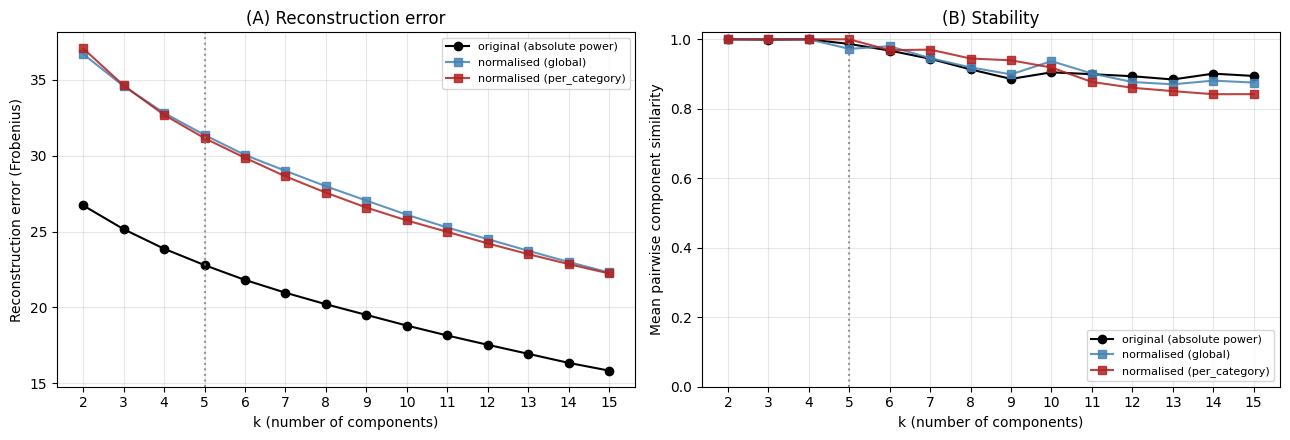

global        : stability at k=5 is 0.9724
per_category  : stability at k=5 is 1.0000

k = 5 is retained for comparability with the main analysis. If stability at
k = 5 has dropped materially for a variant, say so in the text rather than proceeding silently.


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
orig_diag = pd.read_csv(OUTPUT_DIR / "nmf_diagnostics.csv")
for ax, (col, ylab, title) in zip(
        axes,
        [("mean_recon_error", "Reconstruction error (Frobenius)", "(A) Reconstruction error"),
         ("stability_mean", "Mean pairwise component similarity", "(B) Stability")]):
    ax.plot(orig_diag["k"], orig_diag[col], marker="o", label="original (absolute power)", color="black")
    for variant, colour in zip(VARIANTS, ["steelblue", "firebrick"]):
        ax.plot(diagnostics[variant]["k"], diagnostics[variant][col], marker="s",
                label=f"normalised ({variant})", color=colour, alpha=0.85)
    ax.axvline(CHOSEN_K, color="gray", linestyle=":", alpha=0.8)
    ax.set_xlabel("k (number of components)"); ax.set_ylabel(ylab)
    ax.set_title(title); ax.set_xticks(K_RANGE); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[1].set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "normalisation_nmf_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()

for variant in VARIANTS:
    d = diagnostics[variant]
    s_at_k = d.loc[d["k"] == CHOSEN_K, "stability_mean"].values[0]
    log(f"{variant:14s}: stability at k={CHOSEN_K} is {s_at_k:.4f}")
log(f"\nk = {CHOSEN_K} is retained for comparability with the main analysis. If stability at")
log("k = 5 has dropped materially for a variant, say so in the text rather than proceeding silently.")

## Fit at k = 5 and match components to the original solution

NMF does not preserve component ordering, so `comp_1` in the normalised solution is not necessarily `comp_1` in the original. We match the two sets by cosine similarity between their loading vectors (both live in the same 350-dimensional feature space) using the Hungarian algorithm, and report the similarity of each match.

A high similarity means the normalised solution recovered the same pattern; a low one means the pattern itself changed, which is a different — and more interesting — result than the pattern surviving but losing its association with sex.

In [7]:
fits = {}
for variant in VARIANTS:
    X = matrices[variant].values
    errs = [fit_nmf(X, CHOSEN_K, RANDOM_SEED_BASE + i)[2] for i in range(N_INIT)]
    best = int(np.argmin(errs))
    W_, H_, err = fit_nmf(X, CHOSEN_K, RANDOM_SEED_BASE + best)
    labels = [f"comp_{i+1}" for i in range(CHOSEN_K)]
    W_df = pd.DataFrame(W_, index=matrices[variant].index, columns=labels)
    H_df = pd.DataFrame(H_, index=labels, columns=matrices[variant].columns)

    sim = cosine_similarity_matrix(H_df.values, H_orig.values)
    row_ind, col_ind = linear_sum_assignment(-sim)
    mapping = pd.DataFrame({
        "normalised_component": [labels[i] for i in row_ind],
        "matched_original": [H_orig.index[j] for j in col_ind],
        "cosine_similarity": [sim[i, j] for i, j in zip(row_ind, col_ind)],
    }).sort_values("normalised_component").reset_index(drop=True)

    W_df.to_csv(OUTPUT_DIR / f"norm_{variant}_nmf_W.csv")
    H_df.to_csv(OUTPUT_DIR / f"norm_{variant}_nmf_H.csv")
    mapping.to_csv(OUTPUT_DIR / f"norm_{variant}_component_mapping.csv", index=False)
    fits[variant] = {"W": W_df, "H": H_df, "mapping": mapping, "best_init": best, "err": err}

    log(f"\n=== {variant} — component correspondence with the original solution ===")
    log(mapping.round(4).to_string(index=False))
    weak = mapping[mapping["cosine_similarity"] < 0.9]
    if len(weak):
        log(f"[CHECK] {len(weak)} component(s) matched at cosine < 0.90 — the decomposition")
        log("        has genuinely shifted, not merely been relabelled.")


=== global — component correspondence with the original solution ===
normalised_component matched_original  cosine_similarity
              comp_1           comp_2             0.8387
              comp_2           comp_5             0.9673
              comp_3           comp_1             0.9500
              comp_4           comp_3             0.8333
              comp_5           comp_4             0.9485
[CHECK] 2 component(s) matched at cosine < 0.90 — the decomposition
        has genuinely shifted, not merely been relabelled.

=== per_category — component correspondence with the original solution ===
normalised_component matched_original  cosine_similarity
              comp_1           comp_2             0.7998
              comp_2           comp_3             0.8610
              comp_3           comp_5             0.9640
              comp_4           comp_1             0.8807
              comp_5           comp_4             0.9257
[CHECK] 3 component(s) matched at cosine < 

## Re-run the omnibus permutation test

The full test is repeated for all 17 metadata variables, not just sex, so that the FDR correction is computed over the same family as the original and the resulting p-values are directly comparable.

`multi_class="auto"` is dropped from `LogisticRegression` here — it is deprecated in scikit-learn ≥ 1.5 and removed in 1.7. Behaviour is unchanged.

In [8]:
VAR_TYPES = {
    "Age":                                  "continuous",
    "Gender":                               "binary",
    "Residential Area (Urban/Rural)":       "binary",
    "From City":                            "binary",
    "Single/NotSingle":                     "binary",
    "Education":                            "multi",
    "Field of Study":                       "multi",
    "Occupation":                           "multi",
    "# of LanguagesSpeak":                  "continuous",
    "UsedToDoSport":                        "binary",
    "NowDoingSports_aWeek":                 "continuous",
    "PlayingAnInstrument":                  "binary",
    "History of Neurological Disorders":    "binary",
    "Medication Usage":                     "binary",
    "Average Sleep Hours per Night":        "continuous",
    "Smoking (0,1,2,3)":                    "continuous",
    "Alchocol (0,1,2,3)":                   "continuous",
}
VAR_TYPES = {v: t for v, t in VAR_TYPES.items() if v in metadata.columns}

def log_likelihood_logistic(model, X, y):
    proba = np.clip(model.predict_proba(X), 1e-12, 1 - 1e-12)
    if proba.shape[1] == 2:
        return np.sum(y * np.log(proba[:, 1]) + (1 - y) * np.log(proba[:, 0]))
    ll = 0.0
    for idx, cls in enumerate(model.classes_):
        ll += np.sum(np.log(proba[y == cls, idx]))
    return ll

def compute_statistic(X, y, vtype):
    if vtype == "continuous":
        return LinearRegression().fit(X, y).score(X, y)
    if len(np.unique(y)) < 2:
        return np.nan
    try:
        full = LogisticRegression(max_iter=2000, solver="lbfgs").fit(X, y)
        ll_full = log_likelihood_logistic(full, X, y)
    except Exception:
        return np.nan
    _, counts = np.unique(y, return_counts=True)
    priors = counts / counts.sum()
    ll_null = sum(c * np.log(p) for c, p in zip(counts, priors))
    return np.nan if ll_null == 0 else 1 - (ll_full / ll_null)

def run_omnibus(W_df):
    rng = np.random.default_rng(RANDOM_SEED)
    W_std = StandardScaler().fit_transform(W_df.values)
    rows = []
    for var, vtype in VAR_TYPES.items():
        sub = pd.DataFrame({"y": metadata[var]})
        sub["idx"] = np.arange(len(sub))
        sub = sub.dropna()
        if len(sub) < 10:
            rows.append({"variable": var, "type": vtype, "n": len(sub),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "insufficient n"})
            continue
        X_use = W_std[sub["idx"].values]
        y_raw = sub["y"].values
        if vtype == "continuous":
            y_use = pd.to_numeric(y_raw, errors="coerce")
            valid = ~pd.isna(y_use)
            X_use, y_use = X_use[valid], y_use[valid].astype(float)
        else:
            y_use, _ = pd.factorize(y_raw)
        obs = compute_statistic(X_use, y_use, vtype)
        if np.isnan(obs):
            rows.append({"variable": var, "type": vtype, "n": len(y_use),
                         "observed_stat": np.nan, "p_perm": np.nan, "note": "statistic failed"})
            continue
        null = np.zeros(N_PERMUTATIONS)
        y_perm = y_use.copy()
        for i in range(N_PERMUTATIONS):
            rng.shuffle(y_perm)
            null[i] = compute_statistic(X_use, y_perm, vtype)
        rows.append({"variable": var, "type": vtype, "n": len(y_use), "observed_stat": obs,
                     "null_mean": float(np.mean(null)),
                     "null_95pct": float(np.percentile(null, 95)),
                     "p_perm": (np.sum(null >= obs) + 1) / (N_PERMUTATIONS + 1), "note": ""})
    df = pd.DataFrame(rows)
    valid = df["p_perm"].notna()
    if valid.any():
        reject, p_fdr, _, _ = multipletests(df.loc[valid, "p_perm"], alpha=FDR_ALPHA, method="fdr_bh")
        df.loc[valid, "p_fdr"] = p_fdr
        df.loc[valid, "significant_fdr"] = reject
    df["significant_fdr"] = df["significant_fdr"].fillna(False)
    return df.sort_values("p_perm").reset_index(drop=True)

omnibus_results = {}
for variant in VARIANTS:
    t0 = time.time()
    df = run_omnibus(fits[variant]["W"])
    omnibus_results[variant] = df
    df.to_csv(OUTPUT_DIR / f"norm_{variant}_omnibus_results.csv", index=False)
    log(f"\n=== {variant} omnibus ({time.time()-t0:.0f}s) ===")
    log(df[["variable", "type", "n", "observed_stat", "null_mean", "p_perm", "p_fdr",
            "significant_fdr"]].round(4).to_string(index=False))


=== global omnibus (319s) ===
                         variable       type  n  observed_stat  null_mean  p_perm  p_fdr  significant_fdr
                           Gender     binary 86         0.2251     0.0422  0.0002 0.0034             True
   Residential Area (Urban/Rural)     binary 86         0.1744     0.0740  0.0376 0.3195            False
              PlayingAnInstrument     binary 86         0.0854     0.0504  0.1290 0.6450            False
                       Occupation      multi 86         0.2503     0.2274  0.1518 0.6450            False
                              Age continuous 86         0.0846     0.0594  0.2090 0.6731            False
                 Medication Usage     binary 86         0.1654     0.1195  0.2376 0.6731            False
                        Education      multi 86         0.0777     0.0723  0.3743 0.7764            False
                   Field of Study      multi 85         0.2673     0.2623  0.3899 0.7764            False
               

## Per-component follow-up with a fixed group order

The original post-hoc notebook derived the two Mann–Whitney groups from `Series.unique()`, so the sign of the rank-biserial effect depended on which sex happened to appear first in the file. Here the order is fixed explicitly: **positive r means higher in females**, negative means higher in males. This makes the directional claims in the manuscript reproducible rather than incidental.

In [9]:
def per_component_sex(W_df):
    rows = []
    for comp in W_df.columns:
        r = rank_biserial_by_sex(W_df[comp], sex)
        rows.append({"component": comp, "n_f": r["n_f"], "n_m": r["n_m"],
                     "median_f": r["median_f"], "median_m": r["median_m"],
                     "U": r["u"], "rank_biserial": r["r"], "p_raw": r["p"],
                     "direction": "higher in females" if r["r"] > 0 else "higher in males"})
    df = pd.DataFrame(rows)
    valid = df["p_raw"].notna()
    reject, p_fdr, _, _ = multipletests(df.loc[valid, "p_raw"], alpha=FDR_ALPHA, method="fdr_bh")
    df.loc[valid, "p_fdr"] = p_fdr
    df.loc[valid, "significant_fdr"] = reject
    return df.sort_values("p_raw").reset_index(drop=True)

posthoc_results = {}
for variant in VARIANTS:
    df = per_component_sex(fits[variant]["W"])
    mapping = fits[variant]["mapping"].set_index("normalised_component")
    df["matched_original"] = df["component"].map(mapping["matched_original"])
    df["match_cosine"] = df["component"].map(mapping["cosine_similarity"])
    posthoc_results[variant] = df
    df.to_csv(OUTPUT_DIR / f"norm_{variant}_posthoc_per_component.csv", index=False)
    log(f"\n=== {variant} — per-component sex tests ===")
    log(df[["component", "matched_original", "match_cosine", "rank_biserial",
            "direction", "p_raw", "p_fdr", "significant_fdr"]].round(4).to_string(index=False))

# The same fixed-order test applied to the ORIGINAL embedding, for a like-for-like baseline
W_orig = pd.read_csv(OUTPUT_DIR / "nmf_W.csv", index_col="participant_id")
posthoc_baseline = per_component_sex(W_orig)
posthoc_baseline.to_csv(OUTPUT_DIR / "posthoc_per_component_fixed_order.csv", index=False)
log("\n=== original (absolute power), fixed group order ===")
log(posthoc_baseline[["component", "rank_biserial", "direction", "p_raw", "p_fdr",
                      "significant_fdr"]].round(4).to_string(index=False))


=== global — per-component sex tests ===
component matched_original  match_cosine  rank_biserial         direction  p_raw  p_fdr significant_fdr
   comp_3           comp_1        0.9500         0.4913 higher in females 0.0001 0.0004            True
   comp_5           comp_4        0.9485        -0.4556   higher in males 0.0003 0.0007            True
   comp_2           comp_5        0.9673        -0.1158   higher in males 0.3567 0.4515           False
   comp_4           comp_3        0.8333         0.1147 higher in females 0.3612 0.4515           False
   comp_1           comp_2        0.8387        -0.0070   higher in males 0.9586 0.9586           False

=== per_category — per-component sex tests ===
component matched_original  match_cosine  rank_biserial         direction  p_raw  p_fdr significant_fdr
   comp_5           comp_4        0.9257        -0.4199   higher in males 0.0008 0.0041            True
   comp_4           comp_1        0.8807         0.3907 higher in females 0.00

## Side-by-side comparison

In [10]:
comparison = []
orig_row = omnibus_orig[omnibus_orig["variable"] == SEX_COL].iloc[0]
comparison.append({"analysis": "original (absolute power)",
                   "omnibus_stat": orig_row["observed_stat"], "omnibus_p_perm": orig_row["p_perm"],
                   "omnibus_p_fdr": orig_row["p_fdr"], "omnibus_significant": bool(orig_row["significant_fdr"]),
                   "n_components_sig": int(posthoc_baseline["significant_fdr"].sum()),
                   "top_component": posthoc_baseline.iloc[0]["component"],
                   "top_r": posthoc_baseline.iloc[0]["rank_biserial"],
                   "top_p_fdr": posthoc_baseline.iloc[0]["p_fdr"]})
for variant in VARIANTS:
    o = omnibus_results[variant]
    row = o[o["variable"] == SEX_COL].iloc[0]
    ph = posthoc_results[variant]
    comparison.append({"analysis": f"normalised ({variant})",
                       "omnibus_stat": row["observed_stat"], "omnibus_p_perm": row["p_perm"],
                       "omnibus_p_fdr": row["p_fdr"], "omnibus_significant": bool(row["significant_fdr"]),
                       "n_components_sig": int(ph["significant_fdr"].sum()),
                       "top_component": f"{ph.iloc[0]['component']} (~{ph.iloc[0]['matched_original']})",
                       "top_r": ph.iloc[0]["rank_biserial"], "top_p_fdr": ph.iloc[0]["p_fdr"]})

comp_df = pd.DataFrame(comparison)
comp_df.to_csv(OUTPUT_DIR / "normalisation_comparison.csv", index=False)
log("\n" + "=" * 78)
log("COMPARISON: absolute vs. power-normalised")
log("=" * 78)
log(comp_df.round(4).to_string(index=False))


COMPARISON: absolute vs. power-normalised
                 analysis  omnibus_stat  omnibus_p_perm  omnibus_p_fdr  omnibus_significant  n_components_sig    top_component   top_r  top_p_fdr
original (absolute power)        0.2742          0.0002         0.0034                 True                 2           comp_1  0.5768     0.0000
      normalised (global)        0.2251          0.0002         0.0034                 True                 2 comp_3 (~comp_1)  0.4913     0.0004
normalised (per_category)        0.1765          0.0006         0.0102                 True                 2 comp_5 (~comp_4) -0.4199     0.0041


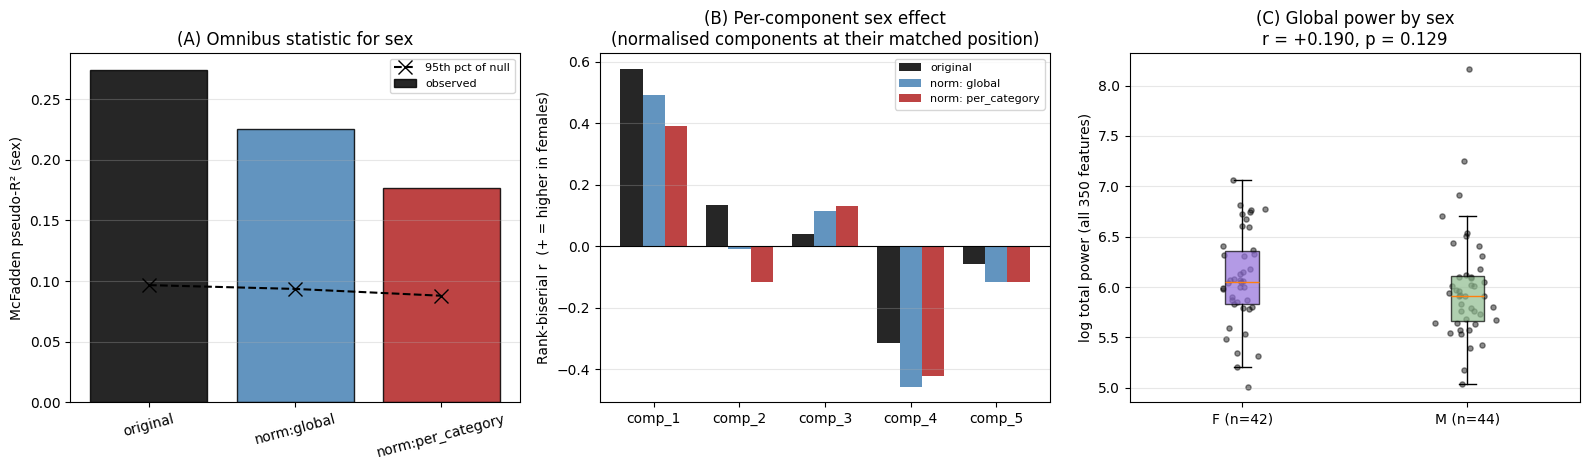

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))

# (A) omnibus statistic for sex, observed vs null 95th percentile
ax = axes[0]
names = ["original"] + [f"norm:{v}" for v in VARIANTS]
obs_vals = [orig_row["observed_stat"]] + [omnibus_results[v].loc[omnibus_results[v]["variable"] == SEX_COL,
                                                                 "observed_stat"].values[0] for v in VARIANTS]
null95 = [orig_row.get("null_95pct", np.nan)] + [omnibus_results[v].loc[omnibus_results[v]["variable"] == SEX_COL,
                                                                        "null_95pct"].values[0] for v in VARIANTS]
x = np.arange(len(names))
ax.bar(x, obs_vals, color=["black", "steelblue", "firebrick"], edgecolor="black", alpha=0.85, label="observed")
ax.plot(x, null95, "kx--", markersize=10, label="95th pct of null")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15)
ax.set_ylabel("McFadden pseudo-R² (sex)")
ax.set_title("(A) Omnibus statistic for sex"); ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

# (B) per-component effect sizes
ax = axes[1]
width = 0.26
comps = [f"comp_{i+1}" for i in range(CHOSEN_K)]
base = posthoc_baseline.set_index("component").reindex(comps)["rank_biserial"]
ax.bar(np.arange(CHOSEN_K) - width, base.values, width, label="original", color="black", alpha=0.85)
for i, (variant, colour) in enumerate(zip(VARIANTS, ["steelblue", "firebrick"])):
    ph = posthoc_results[variant].copy()
    ph["order"] = ph["matched_original"].map({c: j for j, c in enumerate(comps)})
    ph = ph.sort_values("order")
    ax.bar(np.arange(CHOSEN_K) + i * width, ph["rank_biserial"].values, width,
           label=f"norm: {variant}", color=colour, alpha=0.85)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(np.arange(CHOSEN_K)); ax.set_xticklabels(comps)
ax.set_ylabel("Rank-biserial r  (+ = higher in females)")
ax.set_title("(B) Per-component sex effect\n(normalised components at their matched position)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")

# (C) total power by sex
ax = axes[2]
data = [log_total[sex == lvl].dropna() for lvl in SEX_ORDER]
bp = ax.boxplot(data, labels=[f"{SEX_ORDER[0]} (n={len(data[0])})", f"{SEX_ORDER[1]} (n={len(data[1])})"],
                showfliers=False, patch_artist=True)
for patch, colour in zip(bp["boxes"], ["mediumpurple", "darkseagreen"]):
    patch.set_facecolor(colour); patch.set_alpha(0.7)
for i, d in enumerate(data, start=1):
    ax.scatter(np.random.normal(i, 0.05, len(d)), d, color="black", alpha=0.45, s=14)
ax.set_ylabel("log total power (all 350 features)")
ax.set_title(f"(C) Global power by sex\nr = {res_total['r']:+.3f}, p = {res_total['p']:.3f}")
ax.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "normalisation_control.png", dpi=150, bbox_inches="tight")
plt.show()

## Verdict

In [12]:
prim = omnibus_results[PRIMARY_VARIANT]
prim_row = prim[prim["variable"] == SEX_COL].iloc[0]
prim_ph = posthoc_results[PRIMARY_VARIANT]
survived = bool(prim_row["significant_fdr"])

log("\n" + "=" * 78)
log("TOTAL-POWER NORMALISATION CONTROL — VERDICT")
log("=" * 78)
log(f"\nPrimary variant: {PRIMARY_VARIANT}")
log(f"Global power differs by sex: r = {res_total['r']:+.3f}, p = {res_total['p']:.4f}")
log(f"\nSex omnibus, absolute power:   stat = {orig_row['observed_stat']:.4f}, "
    f"p_perm = {orig_row['p_perm']:.4f}, p_fdr = {orig_row['p_fdr']:.4f}")
log(f"Sex omnibus, normalised:       stat = {prim_row['observed_stat']:.4f}, "
    f"p_perm = {prim_row['p_perm']:.4f}, p_fdr = {prim_row['p_fdr']:.4f}")

sig_comps = prim_ph[prim_ph["significant_fdr"]]
log(f"\nComponents surviving within-variable FDR after normalisation: {len(sig_comps)}")
for _, r in sig_comps.iterrows():
    log(f"  {r['component']} (~{r['matched_original']}, cos={r['match_cosine']:.3f}): "
        f"r = {r['rank_biserial']:+.3f} ({r['direction']}), p_fdr = {r['p_fdr']:.4f}")

log("\nInterpretation:")
if survived:
    log("  The sex association SURVIVES normalisation by total power. The effect therefore")
    log("  reflects how power is distributed across channels and bands, not how much power")
    log("  there is overall. This is the topographic account (Jochmann et al., 2023), and it")
    log("  rules out a pure global-gain explanation via skull thickness or electrode contact.")
    log("  Report the normalised result as a control analysis in the Results and cite it in")
    log("  the limitations paragraph where the Hagemann skull-thickness caveat is raised.")
else:
    log("  *** The sex association does NOT survive normalisation by total power. ***")
    log("  The finding is then most plausibly a global gain difference — overall signal")
    log("  amplitude differing between the sexes for anatomical or contact-related reasons")
    log("  (Hagemann et al., 2008) — rather than a topographic difference in cortical")
    log("  activity. The central interpretive claim of the manuscript would need to be")
    log("  reframed accordingly, and this is a change that has to go past Mateo before any")
    log("  text is rewritten.")

sec = omnibus_results["per_category"]
sec_row = sec[sec["variable"] == SEX_COL].iloc[0]
log(f"\nSensitivity check (per-category normalisation): p_fdr = {sec_row['p_fdr']:.4f}, "
    f"significant = {bool(sec_row['significant_fdr'])}")
if bool(sec_row["significant_fdr"]) != survived:
    log("  [CHECK] The two normalisation variants disagree. Report both; the disagreement")
    log("          localises the effect to between-category power structure.")

log("\nFiles saved:")
for variant in VARIANTS:
    for stem in ["nmf_diagnostics", "nmf_W", "nmf_H", "component_mapping",
                 "omnibus_results", "posthoc_per_component"]:
        log(f"  norm_{variant}_{stem}.csv")
for f in ["posthoc_per_component_fixed_order.csv", "normalisation_comparison.csv",
          "normalisation_nmf_diagnostics.png", "normalisation_control.png",
          "normalisation_summary.txt"]:
    log(f"  {f}")

with open(OUTPUT_DIR / "normalisation_summary.txt", "w", encoding="utf-8") as fh:
    fh.write("\n".join(report))


TOTAL-POWER NORMALISATION CONTROL — VERDICT

Primary variant: global
Global power differs by sex: r = +0.190, p = 0.1295

Sex omnibus, absolute power:   stat = 0.2742, p_perm = 0.0002, p_fdr = 0.0034
Sex omnibus, normalised:       stat = 0.2251, p_perm = 0.0002, p_fdr = 0.0034

Components surviving within-variable FDR after normalisation: 2
  comp_3 (~comp_1, cos=0.950): r = +0.491 (higher in females), p_fdr = 0.0004
  comp_5 (~comp_4, cos=0.949): r = -0.456 (higher in males), p_fdr = 0.0007

Interpretation:
  The sex association SURVIVES normalisation by total power. The effect therefore
  reflects how power is distributed across channels and bands, not how much power
  there is overall. This is the topographic account (Jochmann et al., 2023), and it
  rules out a pure global-gain explanation via skull thickness or electrode contact.
  Report the normalised result as a control analysis in the Results and cite it in
  the limitations paragraph where the Hagemann skull-thickness caveat